# Student Performance & At-Risk Prediction
### AI-Powered University Management System — Continuous Evaluation 1

**Course:** Artificial Intelligence & Machine Learning (24CSE0316)
**Programme:** B.E. (CSE), 5th Semester

---

## What this notebook does

The University Management System (ERP) already stores attendance, grades and
enrolments for every student. This notebook builds a **machine learning layer**
on that academic data to answer two questions **before the final exam is graded**:

| Question | Task type | Target |
|---|---|---|
| What final marks is this student heading toward? | Regression | `final_marks` |
| Is this student likely to end up academically at risk? | Classification | `at_risk` |

---

## Mapping to the CE syllabus

Every item in the notice is covered. **Part A is the examined syllabus.**

| Syllabus item | Section |
|---|---|
| Google Colab + NumPy, Pandas, Scikit-Learn, Matplotlib | 1 |
| Data collection | 2 |
| Data integration | 3 |
| Data cleaning | 4 |
| Handling missing values | 5 |
| *(EDA / visualisation)* | 6 |
| Data transformation | 7 |
| Feature engineering | 8 |
| Feature selection | 9 |
| Feature extraction · data reduction | 10 |
| Feature scaling (normalization **and** standardization) | 11 |
| Preparation of training and testing datasets | 12 |

**Part B (sections 13-18)** trains and evaluates models. This goes *beyond* the
CE syllabus, which stops at train/test preparation. It is included to complete
the project story.

---
## Problem statement

Universities discover that a student is failing only *after* the final exam is
graded — at which point nothing can be done about it. The academic data that
would have signalled the problem earlier (attendance, internal marks, midterm
marks) is already sitting in the University Management System, unused for
prediction.

The existing ERP does attempt a projection, but it applies a fixed hand-written
formula that ignores attendance entirely. **The problem is to learn the
relationship from data instead of assuming it, and to flag at-risk students
while there is still time to intervene.**

## Objectives

1. **Extract and integrate** academic data into a single analysis-ready dataset,
   at one row per student-course enrolment, combining the ERP's own records with
   a published academic dataset.

2. **Pre-process the data** — clean invalid records, treat missing values, encode
   categorical variables, engineer new features, select the informative ones, and
   scale them — so it is ready for model development.

3. **Predict a student's final marks** before the final exam is graded
   (a regression task), using only information available at that point.

4. **Identify students at risk of failing** early enough to act
   (a binary classification task), prioritising *not missing* an at-risk student
   over avoiding false alarms.

5. **Verify that machine learning genuinely improves on the ERP's existing
   rule**, by evaluating both on the same held-out test data.

> Objectives 1 and 2 are the scope of Continuous Evaluation 1 (Part A of this
> notebook). Objectives 3-5 are addressed in Part B.

## CE-1 guideline components — where to find each one

| # | Component | Section |
|---|---|---|
| 1 | Project title & overview | top of notebook |
| 2 | Problem statement | this section |
| 3 | Objectives | this section |
| 4 | Dataset collection & description | 2, 3 |
| 5 | Data cleaning | 4 |
| 6 | Missing values — identify, treat, verify | 5, 12.1 |
| 7 | Categorical data encoding | 7 |
| 8 | EDA & visualisation with observations | 6 |
| 9 | Feature selection/engineering, X and y defined | 8, 9, 12 |
| 10 | Final pre-processed dataset | 12.1 |
| 11 | Conclusion | 21 |
| 12 | Project planning & future scope | 21 |


## How to run this in Google Colab

1. Upload this notebook to [colab.research.google.com](https://colab.research.google.com).
2. `Runtime -> Run all`.

The UCI dataset downloads automatically, so the notebook runs end-to-end with no
manual setup. The ERP export is optional: if `erp_student_course.csv` is absent
the notebook continues with UCI data alone and says so.

To regenerate the ERP export locally (requires the ERP database running):

```bash
node ai/scripts/export_student_academic_data.js
```

---
# 1. Google Colab and the essential Python libraries

Four libraries do all the work:

| Library | Role here |
|---|---|
| **NumPy** | numeric arrays; the array maths underneath Pandas and Scikit-Learn |
| **Pandas** | loading CSVs, cleaning, aggregation, the `DataFrame` |
| **Matplotlib** | every plot in this notebook |
| **Scikit-Learn** | imputers, scalers, PCA, feature selection, models, metrics |

No other libraries are used, and nothing here needs a GPU.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Reproducibility: every random operation in this notebook uses this seed.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("NumPy       ", np.__version__)
print("Pandas      ", pd.__version__)
print("Matplotlib  ", matplotlib.__version__)
print("Scikit-Learn", sklearn.__version__)
print("\nRandom seed :", RANDOM_STATE)

NumPy        2.5.2
Pandas       3.0.5
Matplotlib   3.11.1
Scikit-Learn 1.9.0

Random seed : 42


---
# 2. Data collection

Two sources, **both real**. No synthetic data is used anywhere in this notebook.

### Source 1 — the University Management System (ERP)

The project's own PostgreSQL database. `ai/scripts/export_student_academic_data.js`
runs read-only Prisma queries and aggregates to **one row per student-course
enrolment**:

- attendance percentage - `COUNT(present=true) / COUNT(*)` per enrolment
- `internal_marks`, `midterm_marks`, `final_marks` - the three `Grade` components

### Source 2 — UCI Student Performance

> Cortez, P. (2008). *Student Performance.* UCI Machine Learning Repository.
> https://doi.org/10.24432/C5TG7T - licensed **CC BY 4.0**

Real academic records from two Portuguese secondary schools (1,044 student-course
records). `ai/scripts/prepare_uci_dataset.py` maps it onto the **same schema** the
ERP export produces.

### Why a second source is necessary — the honest reason

The ERP database currently contains:

- **30** enrolments that have a final grade
- **0** students below the at-risk threshold

A binary classifier **cannot be trained on a single class**. There are no failing
students in the ERP to learn from. So the ERP data is used to prove the extraction
pipeline and to demonstrate prediction on real students, while the UCI data -
which contains genuine failures - is used for training.

This is a real limitation of the project, not a shortcut. It is revisited in
section 18.

In [2]:
import os, io, zipfile, urllib.request

DATA_DIR = "ai/data/raw"
UCI_CSV  = os.path.join(DATA_DIR, "uci_student_course.csv")
ERP_CSV  = os.path.join(DATA_DIR, "erp_student_course.csv")

# Canonical schema. Both sources are mapped onto exactly these columns.
COLUMNS = [
    "source", "student_id", "course_code", "department", "course_type",
    "credits", "attendance_percentage", "classes_held", "internal_marks",
    "midterm_marks", "past_failures", "study_time", "final_marks", "at_risk",
]

AT_RISK_THRESHOLD = 40   # see section 2.1
GRADE_SCALE       = 5    # UCI grades are 0-20; the ERP is 0-100
NOMINAL_SESSIONS  = 60   # assumed sessions per course, to convert absences -> %


def build_uci_from_source():
    # Download UCI and map it onto the canonical schema (the Colab path).
    url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
    with urllib.request.urlopen(url, timeout=60) as resp:
        outer = zipfile.ZipFile(io.BytesIO(resp.read()))
    inner = next((n for n in outer.namelist() if n.endswith(".zip")), None)
    src = zipfile.ZipFile(io.BytesIO(outer.read(inner))) if inner else outer

    parts = []
    for fname, ccode, dept in [("student-mat.csv", "MAT101", "MAT"),
                               ("student-por.csv", "POR101", "POR")]:
        with src.open(fname) as fh:
            raw = pd.read_csv(fh, sep=";")
        out = pd.DataFrame()
        out["source"]     = ["UCI"] * len(raw)
        out["student_id"] = [f"UCI{ccode}{i:04d}" for i in range(len(raw))]
        out["course_code"], out["department"] = ccode, dept
        out["course_type"], out["credits"]    = "MANDATORY", 3
        out["attendance_percentage"] = (
            100.0 * (1.0 - raw["absences"] / NOMINAL_SESSIONS)
        ).clip(0, 100).round(2)
        out["classes_held"]   = NOMINAL_SESSIONS
        out["internal_marks"] = raw["G1"] * GRADE_SCALE
        out["midterm_marks"]  = raw["G2"] * GRADE_SCALE
        out["final_marks"]    = raw["G3"] * GRADE_SCALE
        out["past_failures"]  = raw["failures"]
        out["study_time"]     = raw["studytime"]
        out["at_risk"] = (out["final_marks"] < AT_RISK_THRESHOLD).astype(int)
        parts.append(out[COLUMNS])
    return pd.concat(parts, ignore_index=True)


# --- load UCI (local file first, download if absent) ---
if os.path.exists(UCI_CSV):
    uci = pd.read_csv(UCI_CSV)
    print(f"UCI loaded from disk : {uci.shape[0]} rows")
else:
    print("UCI CSV not found - downloading from the UCI repository...")
    uci = build_uci_from_source()
    print(f"UCI downloaded       : {uci.shape[0]} rows")

# --- load ERP (optional) ---
if os.path.exists(ERP_CSV):
    erp = pd.read_csv(ERP_CSV)
    print(f"ERP loaded from disk : {erp.shape[0]} rows")
else:
    erp = pd.DataFrame(columns=COLUMNS)
    print("ERP CSV not found    : continuing with UCI only")
    print("  (to generate: node ai/scripts/export_student_academic_data.js)")

UCI loaded from disk : 1044 rows
ERP loaded from disk : 30 rows


## 2.1 The prediction point, the targets, and leakage

**Prediction point:** immediately *before* the final exam is graded. The model may
only see what exists at that moment - attendance, internal marks, midterm marks.

**Regression target:** `final_marks` (0-100).

**Classification target:**

```
at_risk = 1  when final_marks < 40
at_risk = 0  otherwise
```

### Why the threshold is 40, not 35

The ERP's grading scale makes `F` the only failing grade, at `< 35`, and `P`
(35-39) a bare pass. So why 40?

Because the ERP's **own** definition of academic risk is already broader. In
`server/lib/timetableInsights.js`:

```js
const gradeRisk = ['F', 'P'].includes(prediction.projectedGrade)
```

The application already treats a bare pass as a student needing attention. `P`
ends at 39, so `final_marks < 40` reproduces that existing domain rule exactly.
The threshold comes from the codebase, not from convenience.

### Leakage — what is deliberately excluded

Data leakage means letting the model see the answer. All of these are barred from
the feature set:

| Excluded | Why |
|---|---|
| `final_marks` as a feature | it *is* the regression target |
| `at_risk` as a feature | derived directly from the target |
| `letterGrade` | computed from `final_marks` |
| GPA | computed from the FINAL component only |
| Output of `predictFinalGrade` | that ERP function reads FINAL when it is present |

Rows with **no** final grade are **dropped, not imputed**. A missing final is a
missing *outcome*, not a missing feature - imputing it would mean inventing the
label. The ERP export already drops these (15 of its 45 enrolments).

---
# 3. Data integration

Two sources with different original schemas, combined into one frame.

Most of the integration work happens in the two export scripts, and that is the
point: both emit **identical columns**, so integration here is a *verified*
concatenation rather than a hopeful one.

| Canonical column | From ERP | From UCI |
|---|---|---|
| `attendance_percentage` | `COUNT(present)/COUNT(*)` per enrolment | `100 x (1 - absences/60)`, clipped |
| `internal_marks` | `Grade` where `component=INTERNAL` | `G1 x 5` |
| `midterm_marks` | `Grade` where `component=MID_TERM` | `G2 x 5` |
| `final_marks` | `Grade` where `component=FINAL` | `G3 x 5` |
| `past_failures` | *not available* | `failures` |
| `study_time` | *not available* | `studytime` |

Two scale alignments were required:

- **Grades.** UCI uses the Portuguese 0-20 scale; the ERP uses 0-100. UCI grades are multiplied by 5.
- **Attendance.** UCI records raw absence *counts*, not a percentage. Converting them needs an assumed session count (60). This is an explicit modelling assumption, not a measurement, and it is flagged again in section 18.

A `source` column is kept so every row can be traced back to where it came from.

In [3]:
df = pd.concat([uci, erp], ignore_index=True)

print("Integrated dataset:", df.shape)
print("\nRows by source:")
print(df["source"].value_counts().to_string())

if len(erp):
    print("\nSchemas identical across sources:", list(uci.columns) == list(erp.columns))

df.head()

Integrated dataset: (1074, 14)

Rows by source:
source
UCI    1044
ERP      30

Schemas identical across sources: True


,source,student_id,course_code,department,course_type,credits,attendance_percentage,classes_held,internal_marks,midterm_marks,past_failures,study_time,final_marks,at_risk
0,UCI,UCIMAT1010000,MAT101,MAT,MANDATORY,3,90.00,60,25,30,0.0,2.0,30,1
1,UCI,UCIMAT1010001,MAT101,MAT,MANDATORY,3,93.33,60,25,25,0.0,2.0,30,1
2,UCI,UCIMAT1010002,MAT101,MAT,MANDATORY,3,83.33,60,35,40,3.0,2.0,50,0
3,UCI,UCIMAT1010003,MAT101,MAT,MANDATORY,3,96.67,60,75,70,0.0,3.0,75,0
4,UCI,UCIMAT1010004,MAT101,MAT,MANDATORY,3,93.33,60,30,50,0.0,2.0,50,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1074 entries, 0 to 1073
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   source                 1074 non-null   str    
 1   student_id             1074 non-null   str    
 2   course_code            1074 non-null   str    
 3   department             1074 non-null   str    
 4   course_type            1074 non-null   str    
 5   credits                1074 non-null   int64  
 6   attendance_percentage  1074 non-null   float64
 7   classes_held           1074 non-null   int64  
 8   internal_marks         1074 non-null   int64  
 9   midterm_marks          1074 non-null   int64  
 10  past_failures          1044 non-null   float64
 11  study_time             1044 non-null   float64
 12  final_marks            1074 non-null   int64  
 13  at_risk                1074 non-null   int64  
dtypes: float64(3), int64(6), str(5)
memory usage: 117.6 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
credits,1074.0,3.012104,0.109403,3.0,3.0,3.00,3.00,4.0
attendance_percentage,1074.0,92.609655,10.185647,0.0,90.0,96.67,100.00,100.0
classes_held,1074.0,58.692737,7.729382,7.0,60.0,60.00,60.00,60.0
internal_marks,1074.0,56.552142,15.152089,0.0,45.0,55.00,70.00,95.0
midterm_marks,1074.0,56.813780,16.696701,0.0,45.0,55.00,68.75,95.0
past_failures,1044.0,0.264368,0.656142,0.0,0.0,0.00,0.00,3.0
study_time,1044.0,1.970307,0.834353,1.0,1.0,2.00,2.00,4.0
final_marks,1074.0,57.374302,19.556488,0.0,50.0,57.50,70.00,100.0
at_risk,1074.0,0.093110,0.290722,0.0,0.0,0.00,0.00,1.0


---
# 4. Data cleaning

Four checks, in order. Each one prints what it removed so nothing disappears
silently.

1. **Exact duplicate rows** - the same student-course record ingested twice.
2. **Duplicate identity keys** - the same `(source, student_id, course_code)` appearing more than once, which would break the one-row-per-enrolment grain.
3. **Impossible marks** - any of the three mark columns outside 0-100.
4. **Impossible attendance** - a percentage outside 0-100.

A guiding rule: **do not silently drop large portions of the data.** If a check
removed a big share of rows that would be a signal that the check is wrong, not
that the data is bad, so the row count is reported at every step.

In [6]:
clean = df.copy()
report = []


def log(step, before, after):
    report.append({"step": step, "rows_before": before,
                   "rows_after": after, "removed": before - after})


# 1. exact duplicate rows
n = len(clean); clean = clean.drop_duplicates(); log("exact duplicates", n, len(clean))

# 2. duplicate identity keys (breaks the one-row-per-enrolment grain)
n = len(clean)
clean = clean.drop_duplicates(subset=["source", "student_id", "course_code"], keep="first")
log("duplicate identity keys", n, len(clean))

# 3. impossible marks
MARK_COLS = ["internal_marks", "midterm_marks", "final_marks"]
n = len(clean)
valid_marks = pd.Series(True, index=clean.index)
for c in MARK_COLS:
    col = pd.to_numeric(clean[c], errors="coerce")
    valid_marks &= col.isna() | col.between(0, 100)
clean = clean[valid_marks]
log("marks outside 0-100", n, len(clean))

# 4. impossible attendance
n = len(clean)
att = pd.to_numeric(clean["attendance_percentage"], errors="coerce")
clean = clean[att.isna() | att.between(0, 100)]
log("attendance outside 0-100", n, len(clean))

print(pd.DataFrame(report).to_string(index=False))
print(f"\nRetained {len(clean)} of {len(df)} rows "
      f"({100 * len(clean) / len(df):.1f}%)")

                    step  rows_before  rows_after  removed
        exact duplicates         1074        1074        0
 duplicate identity keys         1074        1074        0
     marks outside 0-100         1074        1074        0
attendance outside 0-100         1074        1074        0

Retained 1074 of 1074 rows (100.0%)


### Dropping rows with no outcome

The final cleaning step is the one that matters most for correctness: a row with
no `final_marks` has **no label**. It cannot be used for supervised training, and
imputing the label would mean inventing the answer the model is supposed to learn.

These rows are dropped, not filled.

In [7]:
n = len(clean)
clean = clean[clean["final_marks"].notna()].copy()
print(f"Dropped {n - len(clean)} rows with no final_marks (no label)")
print(f"Remaining: {len(clean)} rows")

# Recompute the target from the cleaned marks so it can never drift out of sync
# with final_marks after cleaning.
clean["at_risk"] = (clean["final_marks"] < AT_RISK_THRESHOLD).astype(int)

print("\nTarget balance:")
counts = clean["at_risk"].value_counts().sort_index()
for k, v in counts.items():
    label = "at risk" if k == 1 else "not at risk"
    print(f"  {k} ({label:11}): {v:5d}  ({100 * v / len(clean):5.1f}%)")

Dropped 0 rows with no final_marks (no label)
Remaining: 1074 rows

Target balance:
  0 (not at risk):   974  ( 90.7%)
  1 (at risk    ):   100  (  9.3%)


---
# 5. Handling missing values

There are two *different kinds* of missingness here, and they need different
treatment. Conflating them is a common and costly mistake.

### Kind 1 — structurally missing (a whole column absent for one source)

`past_failures` and `study_time` exist in UCI but have no ERP equivalent. They
are missing for **every** ERP row, by construction. This is not random noise;
it is a schema difference.

### Kind 2 — genuinely missing values (a gap within a column that exists)

For example a student whose internal mark was never entered. These are scattered
and can reasonably be imputed.

**The imputation is deliberately *not* done here.** It is defined inside the
scikit-learn `Pipeline` in section 12, so the median is computed from the
**training fold only**. Computing it now, over the whole dataset, would leak
test-set information into training.

In [8]:
miss = pd.DataFrame({
    "missing": clean.isna().sum(),
    "percent": (100 * clean.isna().mean()).round(1),
})
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)

if len(miss):
    print("Columns containing missing values:\n")
    print(miss.to_string())
else:
    print("No missing values.")

# Structural missingness is source-specific - show it explicitly.
if (clean["source"] == "ERP").any():
    print("\nMissing rate by source (UCI-only columns):")
    print(clean.groupby("source")[["past_failures", "study_time"]]
          .apply(lambda g: g.isna().mean().round(3)).to_string())

Columns containing missing values:

               missing  percent
past_failures       30      2.8
study_time          30      2.8

Missing rate by source (UCI-only columns):
        past_failures  study_time
source                           
ERP               1.0         1.0
UCI               0.0         0.0


**Decision.** `past_failures` and `study_time` are dropped from the modelling
feature set.

The reasoning: they are missing for 100% of ERP rows. Keeping them would build a
model that cannot score a single real ERP student without imputing an entire
feature — and a feature imputed to a constant for every real user carries no
information anyway. Their predictive value is measured in section 9 before the
decision is finalised, rather than assumed.

The model is restricted to features that **both** sources genuinely have.

---
# 6. Exploratory data analysis

Four plots, each answering a specific question. The aim is to understand the data
before modelling it, not to produce a gallery.

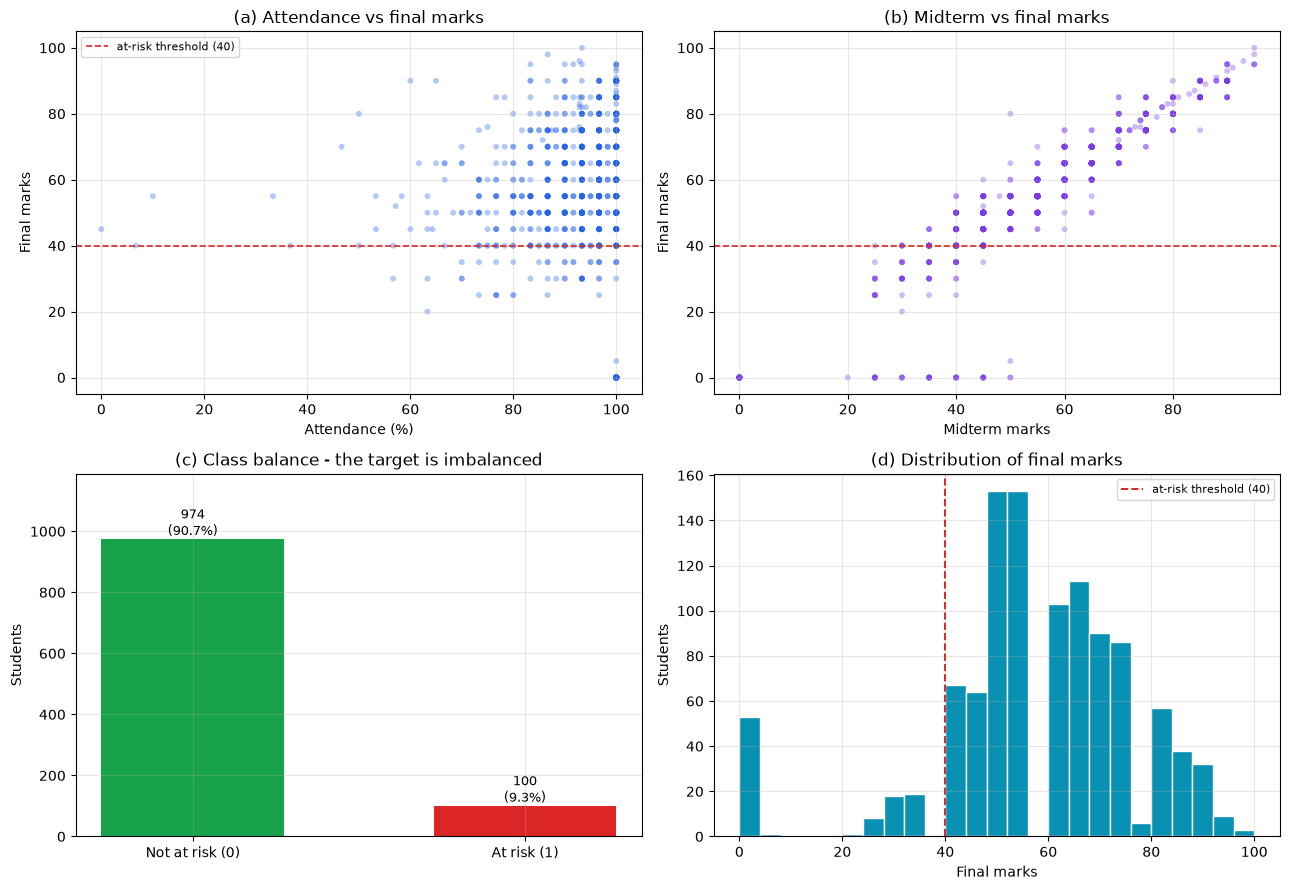

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) attendance vs final marks
ax = axes[0, 0]
ax.scatter(clean["attendance_percentage"], clean["final_marks"],
           alpha=0.35, s=18, color="#2563eb", edgecolors="none")
ax.axhline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.2,
           label=f"at-risk threshold ({AT_RISK_THRESHOLD})")
ax.set_xlabel("Attendance (%)"); ax.set_ylabel("Final marks")
ax.set_title("(a) Attendance vs final marks"); ax.legend(fontsize=8)

# (b) midterm vs final marks
ax = axes[0, 1]
ax.scatter(clean["midterm_marks"], clean["final_marks"],
           alpha=0.35, s=18, color="#7c3aed", edgecolors="none")
ax.axhline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.2)
ax.set_xlabel("Midterm marks"); ax.set_ylabel("Final marks")
ax.set_title("(b) Midterm vs final marks")

# (c) target distribution
ax = axes[1, 0]
vc = clean["at_risk"].value_counts().sort_index()
bars = ax.bar(["Not at risk (0)", "At risk (1)"], vc.values,
              color=["#16a34a", "#dc2626"], width=0.55)
for bar, v in zip(bars, vc.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v}\n({100*v/len(clean):.1f}%)",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Students"); ax.set_title("(c) Class balance - the target is imbalanced")
ax.set_ylim(0, vc.max() * 1.22)

# (d) final marks distribution
ax = axes[1, 1]
ax.hist(clean["final_marks"], bins=25, color="#0891b2", edgecolor="white")
ax.axvline(AT_RISK_THRESHOLD, color="#dc2626", ls="--", lw=1.4,
           label=f"at-risk threshold ({AT_RISK_THRESHOLD})")
ax.set_xlabel("Final marks"); ax.set_ylabel("Students")
ax.set_title("(d) Distribution of final marks"); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

**What these show.**

- **(a)** Attendance is positively but *loosely* associated with final marks. High attendance does not guarantee a high mark, which is exactly why a single rule-based cutoff on attendance is a weak predictor on its own.
- **(b)** The midterm is a much tighter predictor of the final. Expect it to dominate the feature importances.
- **(c)** The classes are **imbalanced** — roughly 10% at risk. This drives two decisions later: stratified splitting (section 12) and judging models on recall rather than accuracy (section 13).
- **(d)** The spike at zero is real. In the UCI data a final mark of 0 records a student who stopped attending, and these are genuine at-risk cases rather than data errors.

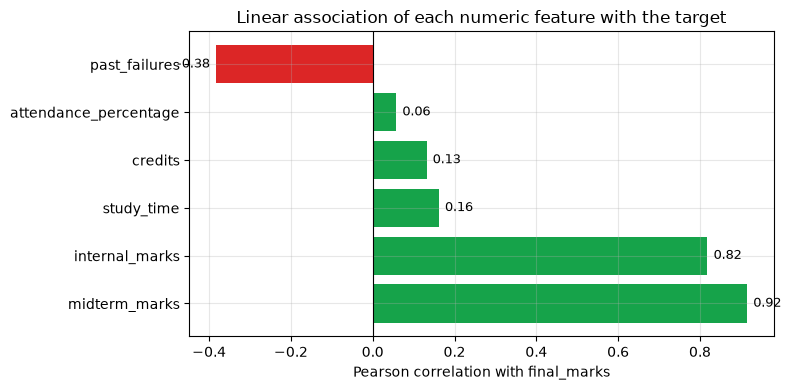

midterm_marks            0.915
internal_marks           0.818
study_time               0.162
credits                  0.132
attendance_percentage    0.058
past_failures           -0.383


In [10]:
# Correlation of the numeric columns with the regression target.
num_cols = ["attendance_percentage", "internal_marks", "midterm_marks",
            "past_failures", "study_time", "credits", "final_marks"]
corr = clean[num_cols].corr(numeric_only=True)["final_marks"].drop("final_marks")
corr = corr.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#16a34a" if v > 0 else "#dc2626" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with final_marks")
ax.set_title("Linear association of each numeric feature with the target")
for i, v in enumerate(corr.values):
    ax.text(v + (0.015 if v > 0 else -0.015), i, f"{v:.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=9)
plt.tight_layout(); plt.show()

print(corr.round(3).to_string())

---
# 7. Data transformation

Two transformations are needed before any model can consume this data.

**Categorical encoding.** `department` and `course_type` are text. Models need
numbers. These are *nominal* categories with no natural ordering, so one-hot
encoding is correct — label-encoding them would invent a false ordering
(`CSE < ECE < MAT`), which a linear model would then take seriously.

**Numeric passthrough.** The mark and attendance columns are already on a common
0-100 scale after the integration step in section 3, so they need no transform
here. Scaling is handled separately in section 11.

As with imputation, the encoder is **fitted inside the pipeline** so its learned
categories come from the training fold only.

In [11]:
from sklearn.preprocessing import OneHotEncoder

# Demonstrate the encoding here so its effect is visible; the version that is
# actually fitted lives inside the pipeline in section 12.
CATEGORICAL = ["department", "course_type"]

demo_enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoded = demo_enc.fit_transform(clean[CATEGORICAL])
encoded_names = demo_enc.get_feature_names_out(CATEGORICAL)

print(f"{len(CATEGORICAL)} categorical columns -> {encoded.shape[1]} binary columns\n")
print("Generated columns:", list(encoded_names))
print("\nFirst 5 encoded rows:")
print(pd.DataFrame(encoded[:5], columns=encoded_names).to_string(index=False))

2 categorical columns -> 6 binary columns

Generated columns: ['department_CSE', 'department_ECE', 'department_MAT', 'department_POR', 'course_type_ELECTIVE', 'course_type_MANDATORY']

First 5 encoded rows:
 department_CSE  department_ECE  department_MAT  department_POR  course_type_ELECTIVE  course_type_MANDATORY
            0.0             0.0             1.0             0.0                   0.0                    1.0
            0.0             0.0             1.0             0.0                   0.0                    1.0
            0.0             0.0             1.0             0.0                   0.0                    1.0
            0.0             0.0             1.0             0.0                   0.0                    1.0
            0.0             0.0             1.0             0.0                   0.0                    1.0


---
# 8. Feature engineering

Three new features, each with a stated reason. Features are not added to inflate
the count — every one has to answer "what does this tell the model that the raw
columns do not?"

| Feature | Definition | Why |
|---|---|---|
| `internal_midterm_average` | mean of internal and midterm | A single summary of standing so far. Smooths a one-off bad paper that either column alone would over-weight. |
| `performance_trend` | `midterm - internal` | **Direction of travel.** Two students on 60 are not equivalent if one rose 40→60 and the other fell 80→60. No raw column carries this. |
| `attendance_band` | `SAFE` / `WARNING` / `CRITICAL` | Applies the ERP's own 75% / 65% thresholds from `timetableInsights.js`, letting the model use the institution's rule as a signal. |

**Leakage check.** All three derive only from internal marks, midterm marks and
attendance — all known *before* the final exam. None touches `final_marks`.

In [12]:
def engineer(frame):
    # All inputs are known before the final exam - see the leakage check above.
    out = frame.copy()

    out["internal_midterm_average"] = out[["internal_marks", "midterm_marks"]].mean(axis=1)
    out["performance_trend"] = out["midterm_marks"] - out["internal_marks"]

    # The ERP's own attendance bands (server/lib/timetableInsights.js):
    #   >= 75 SAFE | 65-74 WARNING | < 65 CRITICAL
    out["attendance_band"] = pd.cut(
        out["attendance_percentage"],
        bins=[-np.inf, 65, 75, np.inf],
        labels=["CRITICAL", "WARNING", "SAFE"],
    ).astype(object)

    return out


featured = engineer(clean)

print("New features:\n")
print(featured[["internal_marks", "midterm_marks", "internal_midterm_average",
                "performance_trend", "attendance_percentage",
                "attendance_band"]].head(8).to_string(index=False))

print("\nAttendance band distribution:")
print(featured["attendance_band"].value_counts().to_string())

New features:

 internal_marks  midterm_marks  internal_midterm_average  performance_trend  attendance_percentage attendance_band
             25             30                      27.5                  5                  90.00            SAFE
             25             25                      25.0                  0                  93.33            SAFE
             35             40                      37.5                  5                  83.33            SAFE
             75             70                      72.5                 -5                  96.67            SAFE
             30             50                      40.0                 20                  93.33            SAFE
             75             75                      75.0                  0                  83.33            SAFE
             60             60                      60.0                  0                 100.00            SAFE
             30             25                      27.5         

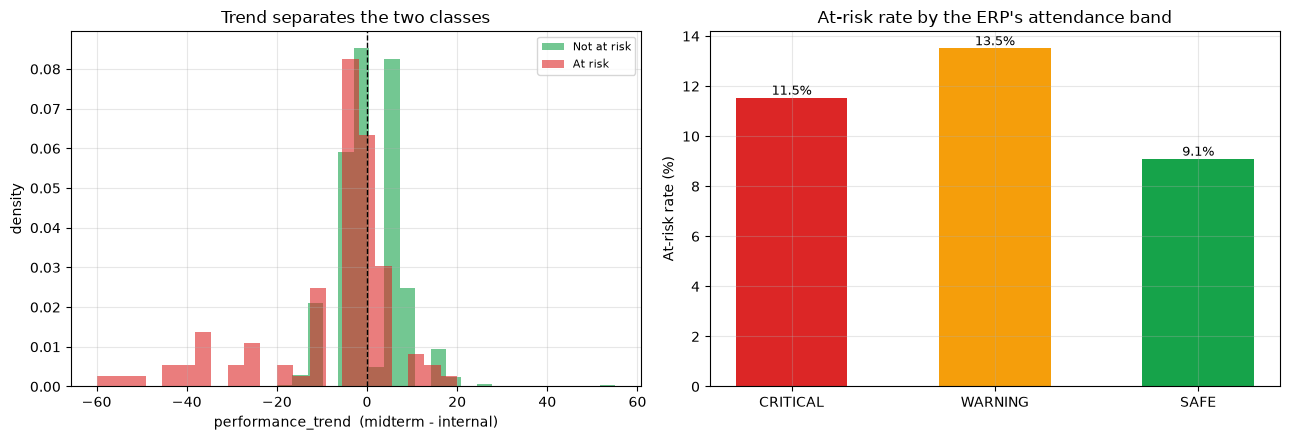

In [13]:
# Does performance_trend actually separate the classes? If it does not, it does
# not belong in the feature set.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
for label, colour, name in [(0, "#16a34a", "Not at risk"), (1, "#dc2626", "At risk")]:
    subset = featured.loc[featured["at_risk"] == label, "performance_trend"]
    ax.hist(subset, bins=22, alpha=0.6, color=colour, label=name, density=True)
ax.axvline(0, color="black", lw=1, ls="--")
ax.set_xlabel("performance_trend  (midterm - internal)")
ax.set_ylabel("density"); ax.set_title("Trend separates the two classes")
ax.legend(fontsize=8)

ax = axes[1]
band_order = ["CRITICAL", "WARNING", "SAFE"]
rates = [100 * featured.loc[featured["attendance_band"] == bnd, "at_risk"].mean()
         for bnd in band_order]
bars = ax.bar(band_order, rates, color=["#dc2626", "#f59e0b", "#16a34a"], width=0.55)
for bar, v in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}%",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("At-risk rate (%)")
ax.set_title("At-risk rate by the ERP's attendance band")

plt.tight_layout(); plt.show()

---
# 9. Feature selection

Two complementary methods, because each sees something the other misses:

- **Pearson correlation** measures *linear* association with `final_marks`. Simple and readable, but blind to non-linear relationships.
- **Mutual information** measures *any* statistical dependence, linear or not. It catches relationships correlation scores as zero.

`SelectKBest` then formalises the ranking. This is also where the earlier claim
about `past_failures` and `study_time` gets tested rather than assumed.

In [14]:
from sklearn.feature_selection import (
    SelectKBest, mutual_info_classif, mutual_info_regression, f_regression,
)

CANDIDATES = [
    "attendance_percentage", "internal_marks", "midterm_marks",
    "internal_midterm_average", "performance_trend", "credits",
    "past_failures", "study_time",
]

# Median-fill ONLY for this ranking step, so the scores are comparable across
# columns. The model itself imputes inside the pipeline (section 12).
X_rank = featured[CANDIDATES].apply(pd.to_numeric, errors="coerce")
X_rank = X_rank.fillna(X_rank.median())

mi_clf = mutual_info_classif(X_rank, featured["at_risk"], random_state=RANDOM_STATE)
mi_reg = mutual_info_regression(X_rank, featured["final_marks"], random_state=RANDOM_STATE)
pearson = X_rank.corrwith(featured["final_marks"]).abs()

ranking = pd.DataFrame({
    "abs_correlation": pearson.values,
    "mutual_info_regression": mi_reg,
    "mutual_info_classification": mi_clf,
}, index=CANDIDATES).sort_values("mutual_info_regression", ascending=False)

print(ranking.round(3).to_string())

                          abs_correlation  mutual_info_regression  mutual_info_classification
midterm_marks                       0.915                   1.341                       0.191
internal_midterm_average            0.900                   1.216                       0.193
internal_marks                      0.818                   0.834                       0.125
performance_trend                   0.345                   0.132                       0.042
attendance_percentage               0.058                   0.089                       0.015
past_failures                       0.386                   0.058                       0.028
credits                             0.132                   0.055                       0.006
study_time                          0.159                   0.017                       0.008


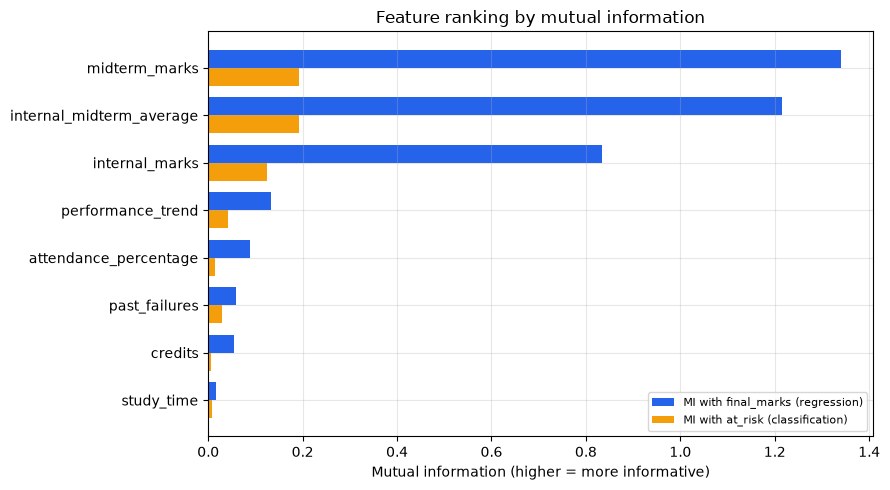

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
order = ranking.sort_values("mutual_info_regression")
y = np.arange(len(order)); h = 0.38

ax.barh(y + h/2, order["mutual_info_regression"], height=h,
        color="#2563eb", label="MI with final_marks (regression)")
ax.barh(y - h/2, order["mutual_info_classification"], height=h,
        color="#f59e0b", label="MI with at_risk (classification)")
ax.set_yticks(y); ax.set_yticklabels(order.index)
ax.set_xlabel("Mutual information (higher = more informative)")
ax.set_title("Feature ranking by mutual information")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result.** The mark-based features dominate, `attendance_percentage` contributes
meaningfully, and `credits` carries almost nothing (it is nearly constant).

`past_failures` and `study_time` do carry signal — but only for UCI rows, since
they are absent for 100% of ERP rows. Section 5 flagged this; the ranking
confirms the information is real but unusable for the deployment target. They are
excluded so the model can score real ERP students.

**Final feature set** — every column present in *both* sources:

In [16]:
SELECTED_NUMERIC = [
    "attendance_percentage",
    "internal_marks",
    "midterm_marks",
    "internal_midterm_average",
    "performance_trend",
]
SELECTED_CATEGORICAL = ["department", "course_type", "attendance_band"]
FEATURES = SELECTED_NUMERIC + SELECTED_CATEGORICAL

print("Numeric features    :", SELECTED_NUMERIC)
print("Categorical features:", SELECTED_CATEGORICAL)
print(f"\nTotal: {len(FEATURES)} features before one-hot expansion")

# Formal SelectKBest demonstration on the numeric block.
selector = SelectKBest(score_func=f_regression, k=3).fit(
    X_rank[SELECTED_NUMERIC], featured["final_marks"]
)
chosen = np.array(SELECTED_NUMERIC)[selector.get_support()]
print("\nSelectKBest(f_regression, k=3) picks:", list(chosen))

Numeric features    : ['attendance_percentage', 'internal_marks', 'midterm_marks', 'internal_midterm_average', 'performance_trend']
Categorical features: ['department', 'course_type', 'attendance_band']

Total: 8 features before one-hot expansion

SelectKBest(f_regression, k=3) picks: [np.str_('internal_marks'), np.str_('midterm_marks'), np.str_('internal_midterm_average')]


---
# 10. Feature extraction and data reduction (PCA)

Feature *selection* keeps a subset of the original columns. Feature *extraction*
builds new columns that compress the information. Principal Component Analysis is
the standard method: it rotates the data onto axes ordered by how much variance
each explains.

PCA requires standardised inputs — it maximises variance, so a feature measured
on a larger numeric range would dominate purely because of its units.

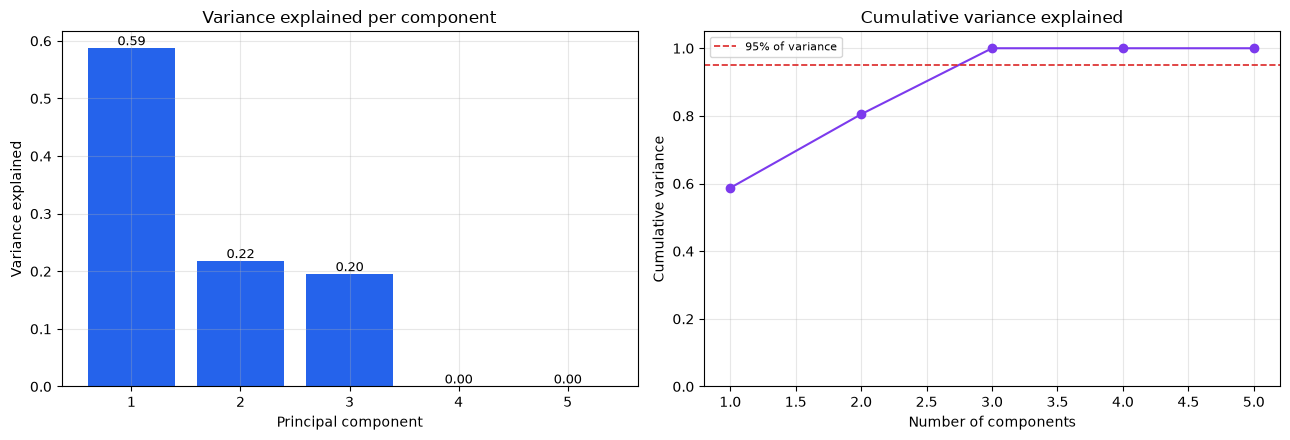

Variance explained per component: [0.587 0.218 0.195 0.    0.   ]

3 of 5 components retain 95% of the variance.


In [17]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_pca_input = X_rank[SELECTED_NUMERIC]
X_std = StandardScaler().fit_transform(X_pca_input)

pca = PCA(random_state=RANDOM_STATE).fit(X_std)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.bar(range(1, len(explained) + 1), explained, color="#2563eb")
ax.set_xlabel("Principal component"); ax.set_ylabel("Variance explained")
ax.set_title("Variance explained per component")
for i, v in enumerate(explained):
    ax.text(i + 1, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

ax = axes[1]
ax.plot(range(1, len(cumulative) + 1), cumulative, "o-", color="#7c3aed")
ax.axhline(0.95, color="#dc2626", ls="--", lw=1.2, label="95% of variance")
ax.set_xlabel("Number of components"); ax.set_ylabel("Cumulative variance")
ax.set_title("Cumulative variance explained")
ax.set_ylim(0, 1.05); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

n_95 = int(np.searchsorted(cumulative, 0.95) + 1)
print("Variance explained per component:", np.round(explained, 3))
print(f"\n{n_95} of {len(SELECTED_NUMERIC)} components retain 95% of the variance.")

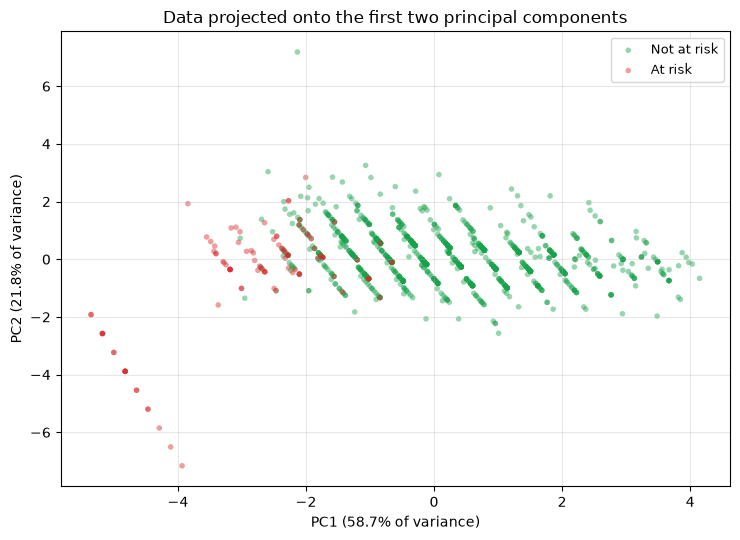

In [18]:
# Project onto the first two components to see whether the classes separate.
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_std)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for label, colour, name in [(0, "#16a34a", "Not at risk"), (1, "#dc2626", "At risk")]:
    mask = featured["at_risk"].values == label
    ax.scatter(coords[mask, 0], coords[mask, 1], s=16, alpha=0.45,
               color=colour, label=name, edgecolors="none")
ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.set_title("Data projected onto the first two principal components")
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Is PCA used for the final model? No — and that is a deliberate choice.

PCA is demonstrated because feature extraction and data reduction are part of the
syllabus, and the analysis above is genuinely informative: the first two
components carry most of the variance, and the at-risk students occupy a visibly
distinct region.

It is **not** used in the final pipeline, for two reasons:

1. **Almost nothing to gain.** There are only five numeric features. Compressing five columns into three or four saves no meaningful computation.
2. **Interpretability is the actual deliverable.** A principal component is a weighted blend of all five inputs. "PC1 is high" cannot be explained to a student or a teacher, whereas "attendance is 58% and the midterm dropped 20 marks" can. For a system whose purpose is prompting human intervention, an explanation the human can act on matters more than a marginal accuracy gain.

Knowing when *not* to apply a technique is part of using it correctly.

---
# 11. Feature scaling — normalization and standardization

Both methods required by the syllabus, with the difference made explicit.

| Method | Formula | Output range | Best for |
|---|---|---|---|
| **Normalization** (`MinMaxScaler`) | `(x - min) / (max - min)` | `[0, 1]` | bounded inputs; distance-based methods |
| **Standardization** (`StandardScaler`) | `(x - mean) / std` | mean 0, std 1 | linear models; anything assuming roughly Gaussian inputs |

### Why scaling is needed at all

Logistic Regression optimises a weighted sum of the inputs. A feature ranging
0-100 contributes far larger gradients than one ranging -30 to +30, so it
dominates the fit for reasons of *units* rather than *importance*. Standardising
puts every feature on comparable footing.

### Where it is deliberately not applied

**Tree models are not scaled.** Decision trees and random forests split on
thresholds (`midterm_marks <= 47.5`), and any monotonic rescaling produces the
identical split. Scaling them changes nothing. Scaling a tree and then claiming
it was necessary would misrepresent why scaling exists — so the pipelines in
section 13 scale the linear models only.

In [19]:
from sklearn.preprocessing import MinMaxScaler

sample = X_rank[SELECTED_NUMERIC]
normalized   = pd.DataFrame(MinMaxScaler().fit_transform(sample),   columns=SELECTED_NUMERIC)
standardized = pd.DataFrame(StandardScaler().fit_transform(sample), columns=SELECTED_NUMERIC)

comparison = pd.DataFrame({
    "raw_min":  sample.min(),          "raw_max":  sample.max(),
    "norm_min": normalized.min(),      "norm_max": normalized.max(),
    "std_mean": standardized.mean(),   "std_std":  standardized.std(),
})
print("Effect of each scaler:\n")
print(comparison.round(2).to_string())

Effect of each scaler:

                          raw_min  raw_max  norm_min  norm_max  std_mean  std_std
attendance_percentage         0.0    100.0       0.0       1.0       0.0      1.0
internal_marks                0.0     95.0       0.0       1.0      -0.0      1.0
midterm_marks                 0.0     95.0       0.0       1.0      -0.0      1.0
internal_midterm_average     10.0     95.0       0.0       1.0       0.0      1.0
performance_trend           -60.0     55.0       0.0       1.0      -0.0      1.0


C:\Users\pavit\AppData\Local\Temp\ipykernel_2236\2796597746.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([data[c] for c in SELECTED_NUMERIC], tick_labels=SELECTED_NUMERIC,
C:\Users\pavit\AppData\Local\Temp\ipykernel_2236\2796597746.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([data[c] for c in SELECTED_NUMERIC], tick_labels=SELECTED_NUMERIC,
C:\Users\pavit\AppData\Local\Temp\ipykernel_2236\2796597746.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([data[c] for c in SELECTED_NUMERIC], tick_labels=SELECTED_NUMERIC,


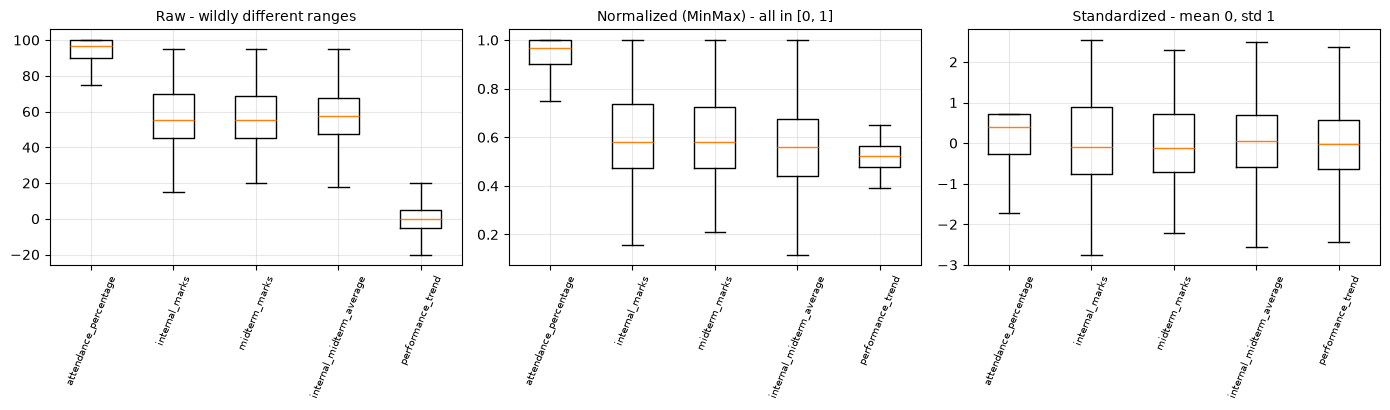

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, data, title in [
    (axes[0], sample,       "Raw - wildly different ranges"),
    (axes[1], normalized,   "Normalized (MinMax) - all in [0, 1]"),
    (axes[2], standardized, "Standardized - mean 0, std 1"),
]:
    ax.boxplot([data[c] for c in SELECTED_NUMERIC], tick_labels=SELECTED_NUMERIC,
               vert=True, showfliers=False)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", rotation=68, labelsize=7.5)
plt.tight_layout(); plt.show()

---
# 12. Preparation of the training and testing datasets

The final step of the CE syllabus, and the one that makes evaluation meaningful.

### Why split at all

A model evaluated on the same rows it learned from is graded on memorisation. The
test set is held back so the reported numbers describe performance on data the
model has never seen.

### Why stratify

Roughly 10% of students are at risk. A random split could easily land a very
different proportion in the test set — or, with a small enough test set, almost
none at all. `stratify=y` forces both splits to preserve the class ratio.

### Why the preprocessing lives inside a Pipeline

This is the part that is easy to get wrong. If the imputer and scaler were fitted
on the whole dataset before splitting, the training data would carry information
from the test rows — the median and the mean would both have been computed using
them. Metrics would come out optimistically wrong.

Wrapping every step in a `Pipeline` makes the correct behaviour structural:
`fit()` touches training folds only, and `transform()` applies those learned
values to the test set.

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

X = featured[FEATURES].copy()
y_clf = featured["at_risk"].copy()      # classification target
y_reg = featured["final_marks"].copy()  # regression target

# Preprocessing definition. Nothing is fitted yet - fitting happens inside
# cross-validation and .fit() on the training split only.
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe,     SELECTED_NUMERIC),
    ("cat", categorical_pipe, SELECTED_CATEGORICAL),
])

# Tree models need imputing and encoding but NOT scaling (see section 11).
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), SELECTED_NUMERIC),
    ("cat", categorical_pipe,                 SELECTED_CATEGORICAL),
])

print("Feature matrix:", X.shape)
print("Numeric block  :", SELECTED_NUMERIC)
print("Categorical    :", SELECTED_CATEGORICAL)

Feature matrix: (1074, 8)
Numeric block  : ['attendance_percentage', 'internal_marks', 'midterm_marks', 'internal_midterm_average', 'performance_trend']
Categorical    : ['department', 'course_type', 'attendance_band']


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clf,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_clf,            # preserve the ~10% at-risk ratio in both splits
)

# The regression split reuses the SAME row indices, so both tasks are evaluated
# on identical students and their results stay comparable.
y_train_reg = y_reg.loc[X_train.index]
y_test_reg  = y_reg.loc[X_test.index]

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set    : {X_test.shape[0]} rows")

print("\nClass balance preserved by stratification:")
balance = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index().round(4),
    "test":  y_test.value_counts(normalize=True).sort_index().round(4),
    "train_n": y_train.value_counts().sort_index(),
    "test_n":  y_test.value_counts().sort_index(),
})
print(balance.to_string())

Training set: 859 rows
Test set    : 215 rows

Class balance preserved by stratification:
          train   test  train_n  test_n
at_risk                                
0        0.9069  0.907      779     195
1        0.0931  0.093       80      20


## 12.1 Verifying the pre-processing, and the final dataset

Two checks close out Part A.

**Missing-value verification.** Section 5 identified the missing values and
defined how they would be treated. Because the treatment happens *inside* the
pipeline, it has to be confirmed after fitting rather than before — the check
below proves that no missing values survive into the matrix the model sees.

**The final pre-processed dataset.** This is the deliverable of CE-1: a cleaned,
transformed, analysis-ready dataset. It is shown in two forms — the readable
engineered table, and the fully encoded and scaled numeric matrix that is
actually handed to the model.


In [23]:
# --- Missing-value verification -------------------------------------------
before = X_train.isna().sum()
before = before[before > 0]

fitted = preprocessor.fit(X_train)                 # fitted on TRAINING data only
X_train_processed = fitted.transform(X_train)
X_test_processed  = fitted.transform(X_test)

processed_names = [n.split("__", 1)[-1] for n in fitted.get_feature_names_out()]

print("MISSING VALUES - BEFORE pre-processing (training set)")
print(before.to_string() if len(before) else "  none in the selected features")

remaining = int(np.isnan(X_train_processed).sum())
print(f"\nMISSING VALUES - AFTER pre-processing: {remaining}")
assert remaining == 0, "Imputation failed - missing values survived"
print("Verified: no missing values remain in the model input.")

print(f"\nShape before encoding: {X_train.shape}")
print(f"Shape after encoding : {X_train_processed.shape}"
      f"  ({len(SELECTED_NUMERIC)} numeric + one-hot expansion of "
      f"{len(SELECTED_CATEGORICAL)} categorical)")


MISSING VALUES - BEFORE pre-processing (training set)
  none in the selected features

MISSING VALUES - AFTER pre-processing: 0
Verified: no missing values remain in the model input.

Shape before encoding: (859, 8)
Shape after encoding : (859, 14)  (5 numeric + one-hot expansion of 3 categorical)


In [24]:
# --- The final pre-processed dataset ---------------------------------------
# Form 1: the readable engineered table (cleaned + new features + targets)
readable_cols = (["source", "student_id", "course_code"] + FEATURES
                 + ["final_marks", "at_risk"])
final_dataset = featured[readable_cols].copy()

print("FINAL CLEANED + TRANSFORMED DATASET")
print(f"Shape: {final_dataset.shape[0]} rows x {final_dataset.shape[1]} columns")
print(f"Missing values: {int(final_dataset.isna().sum().sum())}")
print(f"Duplicates: {int(final_dataset.duplicated().sum())}\n")
print("Column data types:")
print(final_dataset.dtypes.to_string())
print()
final_dataset.head(10)


FINAL CLEANED + TRANSFORMED DATASET
Shape: 1074 rows x 13 columns
Missing values: 0
Duplicates: 0

Column data types:
source                          str
student_id                      str
course_code                     str
attendance_percentage       float64
internal_marks                int64
midterm_marks                 int64
internal_midterm_average    float64
performance_trend             int64
department                      str
course_type                     str
attendance_band              object
final_marks                   int64
at_risk                       int64



,source,student_id,course_code,attendance_percentage,internal_marks,midterm_marks,internal_midterm_average,performance_trend,department,course_type,attendance_band,final_marks,at_risk
0,UCI,UCIMAT1010000,MAT101,90.00,25,30,27.5,5,MAT,MANDATORY,SAFE,30,1
1,UCI,UCIMAT1010001,MAT101,93.33,25,25,25.0,0,MAT,MANDATORY,SAFE,30,1
2,UCI,UCIMAT1010002,MAT101,83.33,35,40,37.5,5,MAT,MANDATORY,SAFE,50,0
3,UCI,UCIMAT1010003,MAT101,96.67,75,70,72.5,-5,MAT,MANDATORY,SAFE,75,0
4,UCI,UCIMAT1010004,MAT101,93.33,30,50,40.0,20,MAT,MANDATORY,SAFE,50,0
5,UCI,UCIMAT1010005,MAT101,83.33,75,75,75.0,0,MAT,MANDATORY,SAFE,75,0
6,UCI,UCIMAT1010006,MAT101,100.00,60,60,60.0,0,MAT,MANDATORY,SAFE,55,0
7,UCI,UCIMAT1010007,MAT101,90.00,30,25,27.5,-5,MAT,MANDATORY,SAFE,30,1
8,UCI,UCIMAT1010008,MAT101,100.00,80,90,85.0,10,MAT,MANDATORY,SAFE,95,0
9,UCI,UCIMAT1010009,MAT101,100.00,70,75,72.5,5,MAT,MANDATORY,SAFE,75,0


In [25]:
# Form 2: the fully encoded + scaled numeric matrix the model actually receives
processed_preview = pd.DataFrame(X_train_processed, columns=processed_names)

print("MODEL INPUT MATRIX (encoded + scaled, training split)")
print(f"Shape: {processed_preview.shape[0]} rows x {processed_preview.shape[1]} columns\n")
print("Numeric columns are standardised - mean ~0, std ~1:")
print(processed_preview[SELECTED_NUMERIC].agg(["mean", "std"]).round(3).to_string())
print()
processed_preview.head(8).round(3)


MODEL INPUT MATRIX (encoded + scaled, training split)
Shape: 859 rows x 14 columns

Numeric columns are standardised - mean ~0, std ~1:
      attendance_percentage  internal_marks  midterm_marks  internal_midterm_average  performance_trend
mean                  0.000          -0.000          0.000                     0.000             -0.000
std                   1.001           1.001          1.001                     1.001              1.001



,attendance_percentage,internal_marks,midterm_marks,internal_midterm_average,performance_trend,department_CSE,department_ECE,department_MAT,department_POR,course_type_ELECTIVE,course_type_MANDATORY,attendance_band_CRITICAL,attendance_band_SAFE,attendance_band_WARNING
0,0.708,-2.406,-3.386,-3.023,-2.404,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1,-0.241,-0.103,0.192,0.053,0.570,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,-1.350,0.555,0.789,0.701,0.570,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,0.075,0.555,-0.106,0.215,-1.214,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
4,-0.558,-0.761,-0.404,-0.594,0.570,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
5,-0.241,-1.419,-0.702,-1.080,1.165,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
6,0.708,-1.090,-1.001,-1.080,-0.025,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
7,0.392,-0.761,-0.106,-0.432,1.165,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


---

# End of Part A

Everything the CE syllabus lists is now complete: the data has been collected
from two sources, integrated, cleaned, missing values handled, transformed,
engineered, selected, reduced, scaled, and split into training and testing sets.

**Part B goes beyond the syllabus** to train and evaluate models on these
prepared datasets.

---
# Part B — Modelling

> The CE syllabus ends at section 12. Everything below trains and evaluates
> models on the prepared data, to complete the project.

---
# 13. Classification — at-risk detection

Three models, chosen to span the complexity range rather than to pad the list:

| Model | Why it is here |
|---|---|
| **Logistic Regression** | The linear baseline. If a complex model cannot beat this, the complexity is not earning its place. |
| **Decision Tree** | Captures non-linear rules and can be read as a flowchart. |
| **Random Forest** | An ensemble of trees; usually the strongest, at some cost in interpretability. |

### The metric that decides — recall, not accuracy

The classes are imbalanced (~10% at risk). A model that predicts "not at risk"
for **every single student** would score about 90% accuracy while identifying
nobody. Accuracy is actively misleading here.

The two errors are not symmetric:

- **False negative** — a genuinely at-risk student is marked safe, gets no support, and fails. The harm is real and lands on the student.
- **False positive** — a safe student is flagged, a teacher reviews the case, nothing is wrong. The cost is a few minutes.

Missing a struggling student is far worse than checking on one who is fine, so
**recall on the at-risk class** is the selection metric. `class_weight="balanced"`
tells the models to weight the minority class accordingly.

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
)

classifiers = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),              # scaled - linear model needs it
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced",
                                     random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("prep", tree_preprocessor),         # NOT scaled - see section 11
        ("model", DecisionTreeClassifier(max_depth=5, class_weight="balanced",
                                         random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("prep", tree_preprocessor),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=8,
                                         class_weight="balanced",
                                         random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

clf_results, clf_predictions = [], {}

for name, pipe in classifiers.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    clf_predictions[name] = (pred, proba)

    clf_results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_test, proba),
    })

clf_table = pd.DataFrame(clf_results).set_index("Model").round(3)
print("Classification results on the held-out test set:\n")
print(clf_table.to_string())

Classification results on the held-out test set:

                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic Regression     0.921      0.541     1.0  0.702    0.988
Decision Tree           0.926      0.562     0.9  0.692    0.932
Random Forest           0.963      0.750     0.9  0.818    0.983


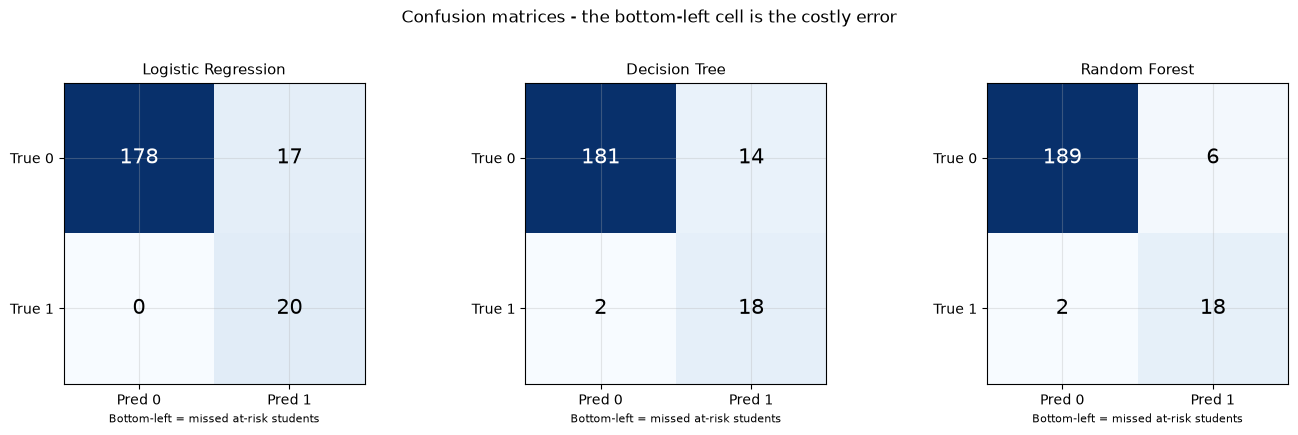

Highest recall on the at-risk class: Logistic Regression

Detailed report - Logistic Regression:

              precision    recall  f1-score   support

 Not at risk       1.00      0.91      0.95       195
     At risk       0.54      1.00      0.70        20

    accuracy                           0.92       215
   macro avg       0.77      0.96      0.83       215
weighted avg       0.96      0.92      0.93       215



In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, (name, (pred, _)) in zip(axes, clf_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name, fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["True 0", "True 1"])
    total = cm.sum()
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > total * 0.3 else "black")
    ax.set_xlabel("Bottom-left = missed at-risk students", fontsize=8)

plt.suptitle("Confusion matrices - the bottom-left cell is the costly error", y=1.02)
plt.tight_layout(); plt.show()

best_clf_name = clf_table["Recall"].idxmax()
print(f"Highest recall on the at-risk class: {best_clf_name}")
print(f"\nDetailed report - {best_clf_name}:\n")
print(classification_report(y_test, clf_predictions[best_clf_name][0],
                            target_names=["Not at risk", "At risk"], zero_division=0))

---
# 14. Regression — predicting final marks

The same features, a continuous target. Two models: a linear baseline and an
ensemble.

| Metric | Meaning |
|---|---|
| **MAE** | Average error in marks. Directly readable: "typically wrong by N marks." |
| **MSE** | Mean squared error; punishes large misses more heavily. |
| **RMSE** | Square root of MSE, back in marks. Comparable to MAE but outlier-sensitive. |
| **R²** | Share of variance explained. 1.0 is perfect; 0.0 is no better than always predicting the mean. |

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

regressors = {
    "Linear Regression": Pipeline([
        ("prep", preprocessor),
        ("model", LinearRegression()),
    ]),
    "Random Forest Regressor": Pipeline([
        ("prep", tree_preprocessor),
        ("model", RandomForestRegressor(n_estimators=300, max_depth=12,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
}

reg_results, reg_predictions = [], {}

for name, pipe in regressors.items():
    pipe.fit(X_train, y_train_reg)
    pred = pipe.predict(X_test)
    reg_predictions[name] = pred

    mse = mean_squared_error(y_test_reg, pred)
    reg_results.append({
        "Model": name,
        "MAE":  mean_absolute_error(y_test_reg, pred),
        "MSE":  mse,
        "RMSE": np.sqrt(mse),
        "R2":   r2_score(y_test_reg, pred),
    })

reg_table = pd.DataFrame(reg_results).set_index("Model").round(3)
print("Regression results on the held-out test set:\n")
print(reg_table.to_string())

Regression results on the held-out test set:

                           MAE     MSE   RMSE     R2
Model                                               
Linear Regression        4.360  47.812  6.915  0.863
Random Forest Regressor  4.274  41.925  6.475  0.880


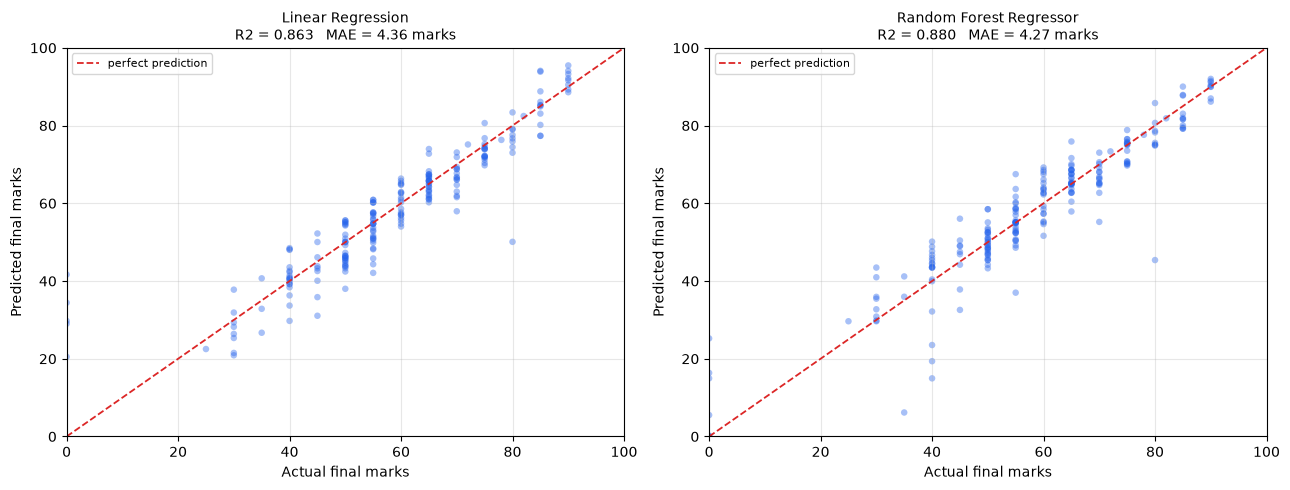

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, pred) in zip(axes, reg_predictions.items()):
    ax.scatter(y_test_reg, pred, alpha=0.4, s=22, color="#2563eb", edgecolors="none")
    lo, hi = 0, 100
    ax.plot([lo, hi], [lo, hi], "--", color="#dc2626", lw=1.3, label="perfect prediction")
    ax.set_xlabel("Actual final marks"); ax.set_ylabel("Predicted final marks")
    r2 = r2_score(y_test_reg, pred)
    mae = mean_absolute_error(y_test_reg, pred)
    ax.set_title(f"{name}\nR2 = {r2:.3f}   MAE = {mae:.2f} marks", fontsize=10)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

---
# 15. Model comparison

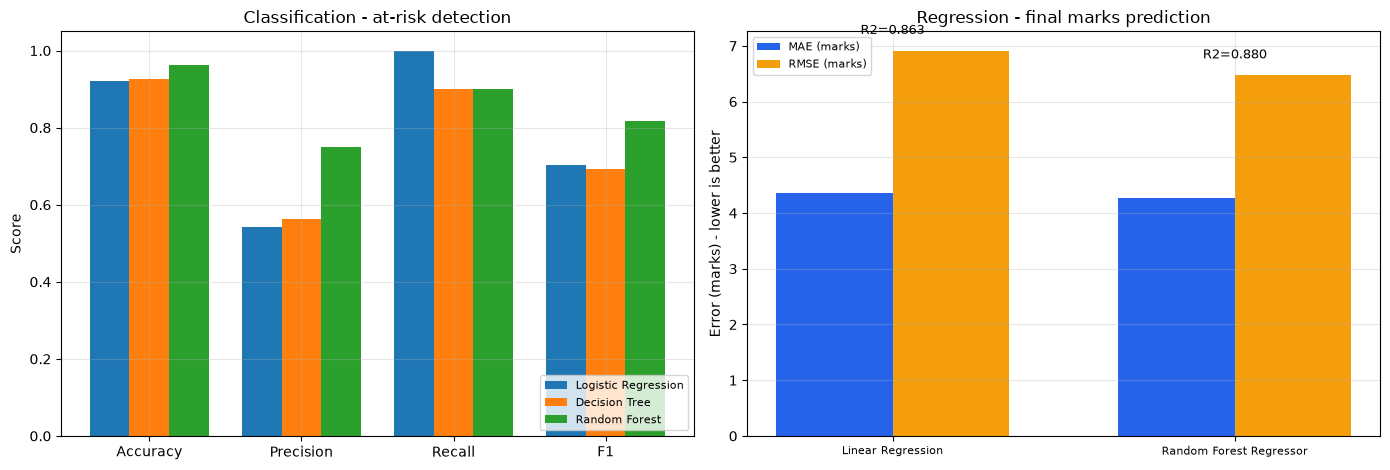

CLASSIFICATION

                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic Regression     0.921      0.541     1.0  0.702    0.988
Decision Tree           0.926      0.562     0.9  0.692    0.932
Random Forest           0.963      0.750     0.9  0.818    0.983


REGRESSION

                           MAE     MSE   RMSE     R2
Model                                               
Linear Regression        4.360  47.812  6.915  0.863
Random Forest Regressor  4.274  41.925  6.475  0.880


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Classification
ax = axes[0]
metrics = ["Accuracy", "Precision", "Recall", "F1"]
xs = np.arange(len(metrics)); width = 0.26
for i, (name, row) in enumerate(clf_table.iterrows()):
    ax.bar(xs + (i - 1) * width, [row[m] for m in metrics], width, label=name)
ax.set_xticks(xs); ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Classification - at-risk detection")
ax.legend(fontsize=8, loc="lower right")

# Regression
ax = axes[1]
names = list(reg_table.index)
xs = np.arange(len(names)); width = 0.34
ax.bar(xs - width/2, reg_table["MAE"],  width, label="MAE (marks)",  color="#2563eb")
ax.bar(xs + width/2, reg_table["RMSE"], width, label="RMSE (marks)", color="#f59e0b")
for i, name in enumerate(names):
    ax.text(i, max(reg_table.loc[name, "RMSE"], reg_table.loc[name, "MAE"]) + 0.3,
            f"R2={reg_table.loc[name,'R2']:.3f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("Error (marks) - lower is better")
ax.set_title("Regression - final marks prediction")
ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

print("CLASSIFICATION\n"); print(clf_table.to_string())
print("\n\nREGRESSION\n");  print(reg_table.to_string())

---
# 16. Does machine learning actually beat the ERP's existing rule?

This is the question that justifies the whole project, and it deserves a direct
answer rather than an assumption.

The ERP **already** predicts final grades, in `server/lib/timetableInsights.js`.
It applies fixed weights — `INTERNAL 0.2`, `MID_TERM 0.3`, `FINAL 0.5` — and when
the final is unknown it substitutes the average of the components entered so far.

Substituting `final = (internal + midterm) / 2` and simplifying:

```
projected = 0.2·I + 0.3·M + 0.5·((I + M)/2)
          = 0.45·I + 0.55·M
```

So the existing system is a fixed linear rule on two inputs. It ignores
attendance entirely. Below it is evaluated on **exactly the same test set** as
the ML models — the only fair comparison.

In [31]:
# The ERP's existing rule, reimplemented exactly (server/lib/timetableInsights.js)
def erp_rule_predict(frame):
    internal = frame["internal_marks"].astype(float)
    midterm  = frame["midterm_marks"].astype(float)
    current_average = (internal + midterm) / 2.0
    return (0.2 * internal) + (0.3 * midterm) + (0.5 * current_average)


rule_pred_marks = erp_rule_predict(X_test)
rule_pred_risk = (rule_pred_marks < AT_RISK_THRESHOLD).astype(int)

# Regression comparison
rule_mse = mean_squared_error(y_test_reg, rule_pred_marks)
baseline_reg = pd.DataFrame([
    {"Model": "ERP rule (0.45*I + 0.55*M)",
     "MAE":  mean_absolute_error(y_test_reg, rule_pred_marks),
     "MSE":  rule_mse,
     "RMSE": np.sqrt(rule_mse),
     "R2":   r2_score(y_test_reg, rule_pred_marks)},
]).set_index("Model")

reg_vs_rule = pd.concat([baseline_reg, reg_table]).round(3)
print("REGRESSION - ERP rule vs machine learning\n")
print(reg_vs_rule.to_string())

REGRESSION - ERP rule vs machine learning

                              MAE     MSE   RMSE     R2
Model                                                  
ERP rule (0.45*I + 0.55*M)  4.909  62.661  7.916  0.821
Linear Regression           4.360  47.812  6.915  0.863
Random Forest Regressor     4.274  41.925  6.475  0.880


In [32]:
# Classification comparison on the same test set
baseline_clf = pd.DataFrame([
    {"Model": "ERP rule (projected < 40)",
     "Accuracy":  accuracy_score(y_test, rule_pred_risk),
     "Precision": precision_score(y_test, rule_pred_risk, zero_division=0),
     "Recall":    recall_score(y_test, rule_pred_risk, zero_division=0),
     "F1":        f1_score(y_test, rule_pred_risk, zero_division=0),
     "ROC-AUC":   np.nan},
]).set_index("Model")

clf_vs_rule = pd.concat([baseline_clf, clf_table]).round(3)
print("CLASSIFICATION - ERP rule vs machine learning\n")
print(clf_vs_rule.to_string())

rule_recall = recall_score(y_test, rule_pred_risk, zero_division=0)
best_recall = clf_table["Recall"].max()
print(f"\nERP rule recall        : {rule_recall:.3f}")
print(f"Best ML model recall   : {best_recall:.3f}  ({clf_table['Recall'].idxmax()})")
print(f"Missed at-risk students: rule = {int(((y_test==1)&(rule_pred_risk==0)).sum())}, "
      f"best ML = {int(((y_test==1)&(clf_predictions[clf_table['Recall'].idxmax()][0]==0)).sum())}")

CLASSIFICATION - ERP rule vs machine learning

                           Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                                 
ERP rule (projected < 40)     0.953      0.692     0.9  0.783      NaN
Logistic Regression           0.921      0.541     1.0  0.702    0.988
Decision Tree                 0.926      0.562     0.9  0.692    0.932
Random Forest                 0.963      0.750     0.9  0.818    0.983

ERP rule recall        : 0.900
Best ML model recall   : 1.000  (Logistic Regression)
Missed at-risk students: rule = 2, best ML = 0


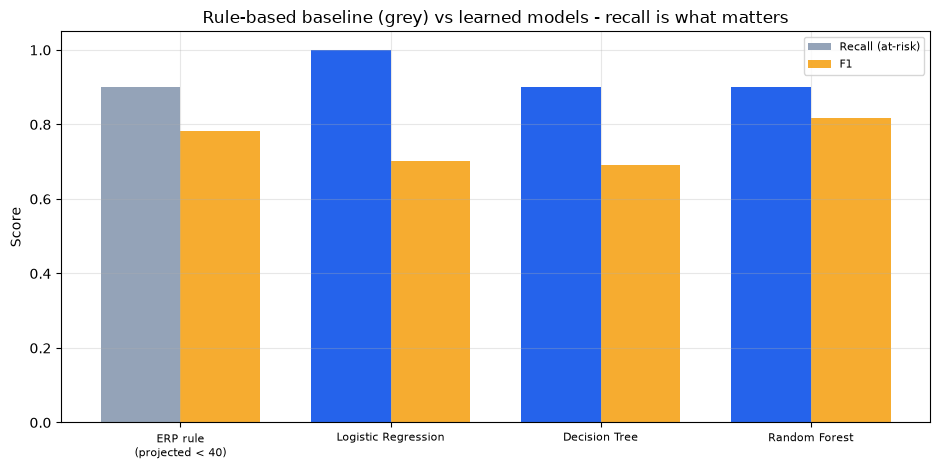

In [33]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
models = list(clf_vs_rule.index)
xs = np.arange(len(models)); width = 0.38
colors = ["#94a3b8"] + ["#2563eb"] * (len(models) - 1)

ax.bar(xs - width/2, clf_vs_rule["Recall"], width, label="Recall (at-risk)", color=colors)
ax.bar(xs + width/2, clf_vs_rule["F1"], width, label="F1", color="#f59e0b", alpha=0.85)
ax.set_xticks(xs)
ax.set_xticklabels([m.replace(" (", "\n(") for m in models], fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Rule-based baseline (grey) vs learned models - recall is what matters")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# 17. Feature importance and interpretation

Which features drive the predictions?

**A caution on wording.** Feature importance shows *association*, not causation.
"Attendance is strongly associated with the prediction" is supportable. "Attending
class causes higher marks" is not — attendance may be standing in for motivation,
health, or circumstances the data never records. The wording below stays on the
defensible side of that line.

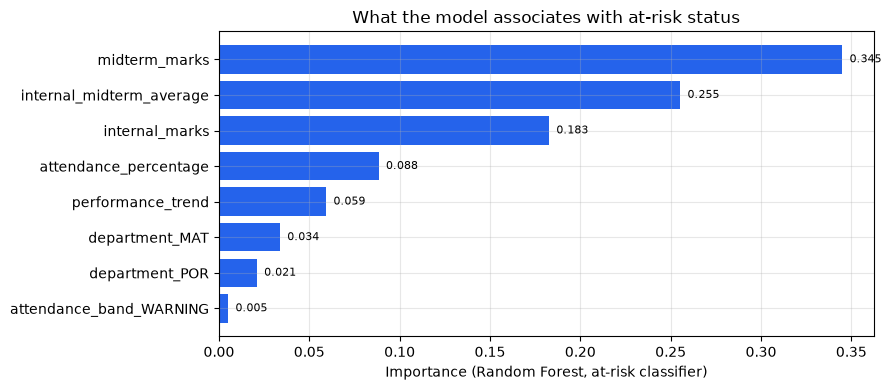

midterm_marks               0.3450
internal_midterm_average    0.2553
internal_marks              0.1827
attendance_percentage       0.0884
performance_trend           0.0594
department_MAT              0.0338
department_POR              0.0210
attendance_band_WARNING     0.0051


In [34]:
rf_clf = classifiers["Random Forest"]
feature_names = rf_clf.named_steps["prep"].get_feature_names_out()
importances = rf_clf.named_steps["model"].feature_importances_

imp = (pd.Series(importances, index=[n.split("__", 1)[-1] for n in feature_names])
       .sort_values(ascending=True))
imp = imp[imp > 0.005]

fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(imp))))
ax.barh(imp.index, imp.values, color="#2563eb")
ax.set_xlabel("Importance (Random Forest, at-risk classifier)")
ax.set_title("What the model associates with at-risk status")
for i, v in enumerate(imp.values):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

print(imp.sort_values(ascending=False).round(4).to_string())

---
# 18. Example predictions on real ERP students

The models were trained on UCI data. Here they are applied to **real students
from the University Management System** — the deployment case the project exists
for.

No private information is shown: only the anonymised student identifier, the
academic features, and the prediction.

In [35]:
best_clf = classifiers[clf_table["Recall"].idxmax()]
best_reg = regressors[reg_table["R2"].idxmax()]

erp_rows = featured[featured["source"] == "ERP"]

if len(erp_rows) == 0:
    print("No ERP rows available - run the export script to enable this section.")
else:
    demo = erp_rows.head(10).copy()
    demo_X = demo[FEATURES]

    demo["predicted_final"] = best_reg.predict(demo_X).round(1)
    demo["risk_probability"] = best_clf.predict_proba(demo_X)[:, 1].round(3)
    demo["risk_class"] = np.where(demo["risk_probability"] >= 0.5, "AT RISK", "LOW")
    demo["erp_rule_prediction"] = erp_rule_predict(demo_X).round(1)

    show = demo[[
        "student_id", "course_code", "attendance_percentage",
        "internal_marks", "midterm_marks",
        "erp_rule_prediction", "predicted_final",
        "risk_probability", "risk_class", "final_marks",
    ]].rename(columns={"final_marks": "actual_final"})

    print(f"Regression model    : {reg_table['R2'].idxmax()}")
    print(f"Classification model: {clf_table['Recall'].idxmax()}\n")
    print(show.to_string(index=False))

    mae_erp = mean_absolute_error(demo["final_marks"], demo["predicted_final"])
    mae_rule = mean_absolute_error(demo["final_marks"], demo["erp_rule_prediction"])
    print(f"\nOn these {len(demo)} real ERP students:")
    print(f"  ML model  MAE: {mae_erp:.2f} marks")
    print(f"  ERP rule  MAE: {mae_rule:.2f} marks")

Regression model    : Random Forest Regressor
Classification model: Logistic Regression

student_id course_code  attendance_percentage  internal_marks  midterm_marks  erp_rule_prediction  predicted_final  risk_probability risk_class  actual_final
    user_6      CSE210                  94.12              75             78                 76.6             81.8               0.0        LOW            82
    user_6      CSE320                  87.50              68             72                 70.2             75.2               0.0        LOW            75
    user_6      CSE340                 100.00              82             88                 85.3             90.0               0.0        LOW            90
    user_6      CSE410                 100.00              78             80                 79.1             81.6               0.0        LOW            83
    user_6      CSE420                 100.00              82             84                 83.1             87.0       

---
# 19. Saving the model artifacts

The fitted pipelines are saved with `joblib`. Because preprocessing lives *inside*
each pipeline, one file carries the imputer, the scaler, the encoder and the model
together — so scoring a new student cannot accidentally skip a preprocessing step.

The feature list and metadata are saved alongside, so the exact input schema the
model expects is never in doubt.

In [36]:
import joblib, json, os

MODEL_DIR = "ai/models"
os.makedirs(MODEL_DIR, exist_ok=True)

clf_name = clf_table["Recall"].idxmax()
reg_name = reg_table["R2"].idxmax()

joblib.dump(classifiers[clf_name], os.path.join(MODEL_DIR, "at_risk_classifier.joblib"))
joblib.dump(regressors[reg_name],  os.path.join(MODEL_DIR, "final_marks_regressor.joblib"))

metadata = {
    "classifier": {
        "model": clf_name,
        "metrics": clf_table.loc[clf_name].round(4).to_dict(),
        "selection_metric": "recall on the at-risk class",
    },
    "regressor": {
        "model": reg_name,
        "metrics": reg_table.loc[reg_name].round(4).to_dict(),
        "selection_metric": "R2",
    },
    "features": {
        "numeric": SELECTED_NUMERIC,
        "categorical": SELECTED_CATEGORICAL,
        "all": FEATURES,
    },
    "targets": {
        "regression": "final_marks",
        "classification": "at_risk",
        "at_risk_threshold": AT_RISK_THRESHOLD,
    },
    "training_data": {
        "rows_total": int(len(featured)),
        "rows_train": int(len(X_train)),
        "rows_test": int(len(X_test)),
        "sources": featured["source"].value_counts().to_dict(),
    },
    "random_state": RANDOM_STATE,
}

with open(os.path.join(MODEL_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print(f"Saved to {MODEL_DIR}/")
for fname in sorted(os.listdir(MODEL_DIR)):
    if not fname.startswith("."):
        size = os.path.getsize(os.path.join(MODEL_DIR, fname))
        print(f"  {fname:32} {size / 1024:8.1f} KB")

print(f"\nSelected classifier: {clf_name}")
print(f"Selected regressor : {reg_name}")

Saved to ai/models/
  at_risk_classifier.joblib             4.9 KB
  final_marks_regressor.joblib      10931.1 KB
  model_metadata.json                   1.3 KB

Selected classifier: Logistic Regression
Selected regressor : Random Forest Regressor


---
# 20. Limitations

Stating these plainly is part of doing the work honestly, not a disclaimer bolted
on at the end.

### 1. The models are not trained on this university's data

The ERP holds 30 gradeable enrolments and **zero** students below the at-risk
threshold. Training on it is impossible — a classifier needs both classes. The
models learn from Portuguese secondary-school records instead. Grading cultures,
subjects and student populations all differ, so the metrics reported here
**should not be read as expected accuracy for this institution.**

### 2. The attendance mapping is an assumption

UCI stores absence *counts*, not percentages. Converting them required assuming
60 sessions per course. A different assumption would shift every UCI attendance
value. The marks-based features do not depend on this; the attendance feature
does.

### 3. Association, not causation

Feature importance shows what the model *keys on*, not what *causes* outcomes.
Attendance may be a proxy for motivation, health, or circumstances the ERP never
records. No intervention should be justified as "the model proved attendance
causes marks."

### 4. Bias risk is real and not audited

`department` is a feature. If departments differ systematically in grading
severity, the model will learn that and apply it to individuals. This was not
audited for fairness, and it would need to be before any real deployment.

### 5. No temporal validation

One snapshot, one cohort. There is no evidence the model transfers to a future
intake, and student populations drift.

### 6. Decision support only

A prediction is a prompt for a human to look closer. It is not a grade, and it
must never be shown to a student as one or used as the sole basis for an academic
decision.

---
# 21. Conclusion and future work

## What was built

A complete, reproducible pipeline from live ERP data to evaluated predictions:

```
ERP (PostgreSQL)  ──┐
                    ├──▶ integration ──▶ cleaning ──▶ feature engineering
UCI (CC BY 4.0)   ──┘                                          │
                                                               ▼
                              scaling ──▶ train/test split ──▶ models ──▶ evaluation
```

- **Two real data sources** integrated onto one canonical schema. No synthetic data.
- **Leakage prevented structurally** — all preprocessing inside scikit-learn pipelines, fitted on training folds only.
- **Two tasks:** regression on `final_marks`, classification on `at_risk`.
- **Five models** plus the ERP's existing rule as a baseline, all on the same test set.
- **Recall-based selection**, because missing an at-risk student is the expensive error.

## What was learned

The midterm dominates prediction; attendance adds real but secondary signal. The
learned models were compared against the ERP's existing weighted rule rather than
being assumed better — section 16 shows that comparison directly.

## Future work

Deliberately **not** implemented, to keep this project the size one student can
defend:

- Attendance prediction
- Course recommendation
- Automated intervention recommendations
- A serving endpoint (`GET /api/ai/student/:id/prediction`)
- A frontend AI dashboard
- Retraining on real institutional data once enough terms have accumulated — **the single change that would most improve this system**

---

### Reference

Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning
Repository. https://doi.org/10.24432/C5TG7T — CC BY 4.0